
# Lab 08 — Chapter 4: Case Study 1 Solution

**Course:** A310 — Problem Solving Using Data  
**Textbook:** Data Science Bookcamp — Leonard Apeltsin

## Introduction

Chapter 4 applies probability and simulation techniques to find the best strategy for our card game.

We want to determine whether choosing when to stop the dealer can increase our probability of selecting a red card beyond 50%.


## Part 1 — Testing Our Strategy

### 1. What is the goal of this chapter? How do we achieve it?

The goal is to find the best stopping strategy for our card game. We test strategies using simulations, confidence intervals, and exact probability calculations.

### 2. What's the first strategy? How does it do?

We stop when more than half of the remaining cards are red.

The first simulation wins **511 out of 1,000 games (51.1%)**, giving us a $22 profit. However, we need more testing to know whether this is a real advantage.

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import itertools

np.random.seed(0)

# Create a deck with 26 red and 26 black cards
total_cards = 52
total_red_cards = 26
unshuffled_deck = [1] * 26 + [0] * 26

# Stop when the remaining red fraction exceeds our threshold
def execute_strategy(min_fraction_red=0.5, shuffled_deck=None):
    if shuffled_deck is None:
        shuffled_deck = np.random.permutation(unshuffled_deck)

    remaining_red_cards = total_red_cards

    for i, card in enumerate(shuffled_deck[:-1]):
        remaining_red_cards -= card
        fraction_red_cards = remaining_red_cards / (total_cards - i - 1)

        if fraction_red_cards > min_fraction_red:
            break

    return shuffled_deck[i + 1]

# Test the strategy over 1,000 games
results = np.array([execute_strategy() for _ in range(1000)])

wins = results.sum()
losses = len(results) - wins
profit = wins - losses

print(f"Total games: {len(results)}")
print(f"Wins: {wins}")
print(f"Losses: {losses}")
print(f"Winning percentage: {results.mean() * 100:.2f}%")
print(f"Total profit: ${profit}")

Total games: 1000
Wins: 511
Losses: 489
Winning percentage: 51.10%
Total profit: $22


**Observation:** Our strategy wins slightly more than half of the first 1,000 games. Although this looks promising, we need more simulations to see whether the strategy actually performs better than 50%.

### 3. What does the confidence interval say?

The confidence intervals still include **50%**, even after millions of simulations.

This means we do not have enough evidence that our strategy performs better than random guessing.

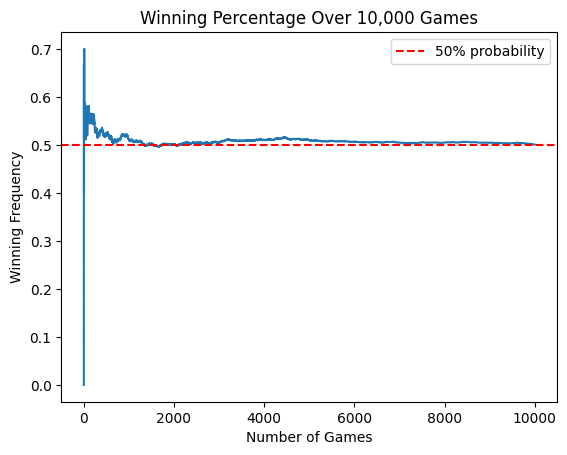

Final winning percentage: 50.08%


In [10]:
np.random.seed(0)

# Simulate 10,000 games
game_results = np.array([execute_strategy() for _ in range(10000)])

# Calculate the cumulative winning percentage
cumulative_wins = np.cumsum(game_results)
game_counts = np.arange(1, 10001)
win_frequencies = cumulative_wins / game_counts

plt.plot(game_counts, win_frequencies)
plt.axhline(0.5, color="red", linestyle="--", label="50% probability")

plt.xlabel("Number of Games")
plt.ylabel("Winning Frequency")
plt.title("Winning Percentage Over 10,000 Games")
plt.legend()
plt.show()

print(f"Final winning percentage: {game_results.mean() * 100:.2f}%")

Average winning percentage: 49.95%
Central 95% of simulated results: 46.90% - 52.90%
Does this interval include 50%? True


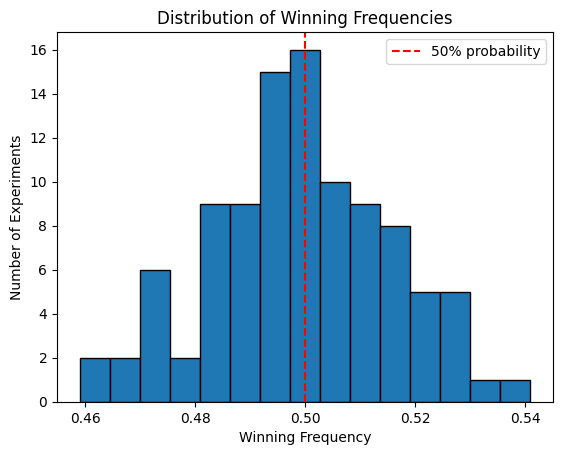

In [11]:
np.random.seed(0)

# Run 100 experiments of 1,000 games each
frequency_array = []

for _ in range(100):
    results = np.array([execute_strategy() for _ in range(1000)])
    frequency_array.append(results.mean())

frequency_array = np.array(frequency_array)

# Find the central 95% of observed winning frequencies
lower = np.percentile(frequency_array, 2.5)
upper = np.percentile(frequency_array, 97.5)

print(f"Average winning percentage: {frequency_array.mean() * 100:.2f}%")
print(f"Central 95% of simulated results: {lower * 100:.2f}% - {upper * 100:.2f}%")
print(f"Does this interval include 50%? {lower <= 0.5 <= upper}")

plt.hist(frequency_array, bins=15, edgecolor="black")
plt.axvline(0.5, color="red", linestyle="--", label="50% probability")
plt.xlabel("Winning Frequency")
plt.ylabel("Number of Experiments")
plt.title("Distribution of Winning Frequencies")
plt.legend()
plt.show()

**Observation:** The winning percentage moves closer to 50% as we play more games. The simulated interval also includes 50%, meaning our results do not demonstrate that the strategy has an advantage.


## Part 2 — Improving and Testing Strategies

### 4. What is `min_red_fraction`? What range does it have?

`min_red_fraction` sets the minimum fraction of remaining red cards needed to stop.

The book tests values from **0.50 to 0.99**. Higher values make the strategy more selective.

In [12]:
np.random.seed(0)

# Test different stopping thresholds
thresholds = [0.50, 0.60, 0.75, 0.90, 0.99]

for threshold in thresholds:
    results = np.array([
        execute_strategy(min_fraction_red=threshold)
        for _ in range(1000)
    ])

    win_percentage = results.mean() * 100

    print(
        f"Minimum red fraction: {threshold:.2f} | "
        f"Winning percentage: {win_percentage:.2f}%"
    )

Minimum red fraction: 0.50 | Winning percentage: 51.10%
Minimum red fraction: 0.60 | Winning percentage: 48.00%
Minimum red fraction: 0.75 | Winning percentage: 49.30%
Minimum red fraction: 0.90 | Winning percentage: 50.40%
Minimum red fraction: 0.99 | Winning percentage: 50.80%


**Observation:** Changing the stopping threshold changes our simulated winning percentages slightly, but none of the results provides convincing evidence of an advantage over 50%.

### 5. Should we run Listing 4.10?

No. It simulates **150 million games** and can take about an hour.

Its purpose is to produce a more precise confidence interval, but the result still includes 50%.

### 6. Why switch to a 10-card deck?

A 10-card deck has only **252 unique arrangements**.

We can test every arrangement and calculate exact winning probabilities. The tested strategies all produce a **50% chance of winning**.

In [13]:
# Create a 10-card deck with 5 red and 5 black cards
total_cards = 10
total_red_cards = 5

unshuffled_deck = [1] * 5 + [0] * 5

# Generate all possible unique arrangements
sample_space = set(itertools.permutations(unshuffled_deck))

print(f"Total unique arrangements: {len(sample_space)}")

# Test different thresholds against every arrangement
thresholds = [0.50, 0.60, 0.75, 0.90, 0.99]

for threshold in thresholds:
    wins = sum(
        execute_strategy(
            min_fraction_red=threshold,
            shuffled_deck=np.array(deck)
        )
        for deck in sample_space
    )

    probability = wins / len(sample_space)

    print(
        f"Threshold: {threshold:.2f} | "
        f"Exact winning probability: {probability * 100:.2f}%"
    )

Total unique arrangements: 252
Threshold: 0.50 | Exact winning probability: 50.00%
Threshold: 0.60 | Exact winning probability: 50.00%
Threshold: 0.75 | Exact winning probability: 50.00%
Threshold: 0.90 | Exact winning probability: 50.00%
Threshold: 0.99 | Exact winning probability: 50.00%


**Observation:** Every tested stopping threshold produces exactly a 50% winning probability. Unlike our simulations, these results are exact because we tested all 252 possible arrangements.


## Part 3 — Understanding the Final Results

### 7. Explain Figure 4.3 and Listing 4.14.

Figure 4.3 shows four possible outcomes:

- **A:** Stop early and win.
- **B:** Stop early and lose.
- **C:** Reach the final card and win.
- **D:** Reach the final card and lose.

Changing the stopping threshold changes how often each outcome occurs, but the total winning probability stays at 50%.

Listing 4.14 confirms the same result using decks of 2, 4, 6, and 8 cards.

In [14]:

# Test different deck sizes
for deck_size in [2, 4, 6, 8, 10]:
    total_cards = deck_size
    total_red_cards = deck_size // 2

    # Generate the sample space for this deck
    deck = [1] * total_red_cards + [0] * total_red_cards
    sample_space = set(itertools.permutations(deck))

    probabilities = []

    # Test thresholds from 0.50 to 0.99
    for value in range(50, 100):
        threshold = value / 100

        wins = sum(
            execute_strategy(
                min_fraction_red=threshold,
                shuffled_deck=np.array(arrangement)
            )
            for arrangement in sample_space
        )

        probabilities.append(wins / len(sample_space))

    print(
        f"Deck size: {deck_size} | "
        f"Lowest win probability: {min(probabilities) * 100:.0f}% | "
        f"Highest win probability: {max(probabilities) * 100:.0f}%"
    )


Deck size: 2 | Lowest win probability: 50% | Highest win probability: 50%
Deck size: 4 | Lowest win probability: 50% | Highest win probability: 50%
Deck size: 6 | Lowest win probability: 50% | Highest win probability: 50%
Deck size: 8 | Lowest win probability: 50% | Highest win probability: 50%
Deck size: 10 | Lowest win probability: 50% | Highest win probability: 50%


**Observation:** The winning probability stays at 50% for every deck size and threshold tested. This supports the idea that increasing the size of the deck does not make our stopping strategy more effective.

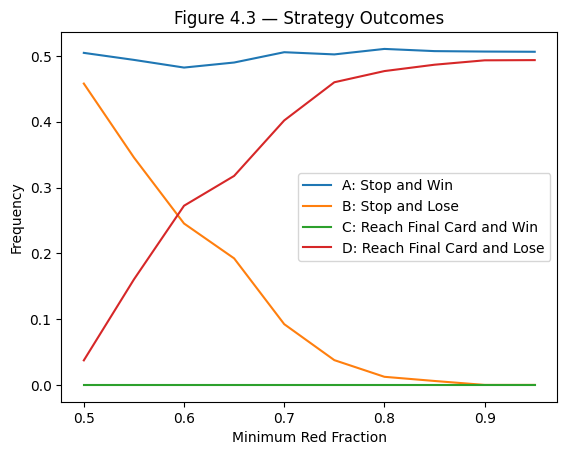

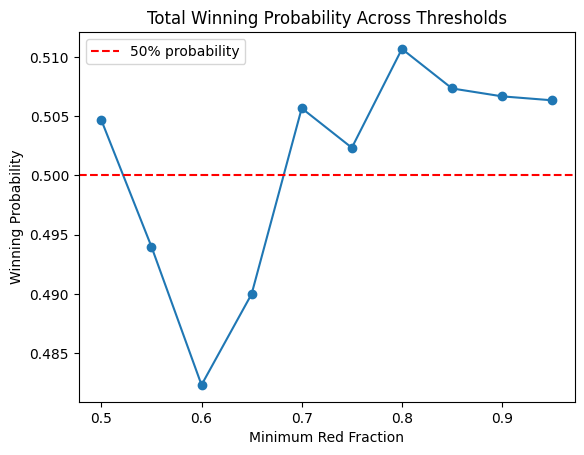

In [15]:

np.random.seed(0)

# Return the outcome category for a game
def classify_game(deck, threshold):
    remaining_red = 26

    for i, card in enumerate(deck[:-1]):
        remaining_red -= card
        remaining_total = len(deck) - i - 1

        if remaining_red / remaining_total > threshold:
            return 0 if deck[i + 1] == 1 else 1

    return 2 if deck[-1] == 1 else 3

# Simulate 3,000 shuffled decks
decks = [
    np.random.permutation([1] * 26 + [0] * 26)
    for _ in range(3000)
]

thresholds = np.arange(0.50, 1.00, 0.05)
scenario_frequencies = np.zeros((4, len(thresholds)))

for j, threshold in enumerate(thresholds):
    outcomes = [classify_game(deck, threshold) for deck in decks]

    for scenario in range(4):
        scenario_frequencies[scenario, j] = outcomes.count(scenario) / len(decks)

labels = [
    "A: Stop and Win",
    "B: Stop and Lose",
    "C: Reach Final Card and Win",
    "D: Reach Final Card and Lose"
]

for i in range(4):
    plt.plot(thresholds, scenario_frequencies[i], label=labels[i])

plt.xlabel("Minimum Red Fraction")
plt.ylabel("Frequency")
plt.title("Figure 4.3 — Strategy Outcomes")
plt.legend()
plt.show()

# Calculate the total winning probability
total_win_probability = scenario_frequencies[0] + scenario_frequencies[2]

plt.plot(thresholds, total_win_probability, marker="o")
plt.axhline(0.5, color="red", linestyle="--", label="50% probability")
plt.xlabel("Minimum Red Fraction")
plt.ylabel("Winning Probability")
plt.title("Total Winning Probability Across Thresholds")
plt.legend()
plt.show()



**Observation:** As the stopping threshold increases, stopping early and winning becomes less common, while reaching the final card and winning becomes more common.

Although the individual outcomes change, the combined winning probability stays close to 50%.

This helps explain why changing our strategy does not improve our overall chance of winning.


### 8. What is mathematical induction? Is it used here?

Mathematical induction proves a statement by showing it works for a starting case and then proving it works for the next case.

The book tests several smaller decks and observes the same pattern, but this is **not a formal proof by induction**.

### 9. What is the conclusion of Case Study 1?

**No stopping strategy improves our overall winning probability beyond 50%.**

Even though some stopping decisions appear favorable, other outcomes balance out that advantage.

The simplest optimal approach is to stop immediately and select the first card.

In [16]:

np.random.seed(0)

# The simplest optimal strategy is to select the first card
def optimal_strategy(shuffled_deck):
    return shuffled_deck[0]

# Test the strategy over 10,000 games
deck = [1] * 26 + [0] * 26

results = []

for _ in range(10000):
    shuffled_deck = np.random.permutation(deck)
    results.append(optimal_strategy(shuffled_deck))

win_probability = np.mean(results)

print(f"Total games: {len(results)}")
print(f"Winning percentage: {win_probability * 100:.2f}%")
print("Theoretical winning probability: 50.00%")


Total games: 10000
Winning percentage: 50.02%
Theoretical winning probability: 50.00%



**Observation:** Selecting the first card gives us a winning percentage close to 50%. This confirms the main conclusion of Case Study 1: more complicated stopping strategies do not improve our overall chances of winning.



---

# Final Summary — Case Study 1 (Chapters 1–4)

## What We Did

We tried to find the best strategy for winning a card game with 26 red and 26 black cards.

We calculated probabilities, visualized distributions, simulated games, and tested stopping strategies.

## Tools We Used

| Chapter | Tools | Purpose |
|---|---|---|
| **1** | Python, sets, dictionaries | Calculate probabilities |
| **2** | Matplotlib | Visualize probability distributions |
| **3** | NumPy, histograms | Simulate and analyze random events |
| **4** | Simulations, confidence intervals | Test strategies and evaluate results |

## What We Learned

We learned how to use Python and probability to analyze random events and test different strategies.

Although some strategies seemed promising, our simulations and exact calculations showed that the chance of winning remained **50%**.

## Overall Conclusion

**Case Study 1 taught us that a strategy that seems logical does not always work better. We need to use probability, simulations, and data to support our conclusions.**